# ¿Calcular o pensar con datos? Una experiencia con el clima de Caucasia

### Intención de este cuaderno
Hacer **visible** la diferencia entre dos maneras de enseñar la misma estadística:

| | Enseñar a **calcular** | Enseñar a **pensar estadísticamente** |
|---|---|---|
| Punto de partida | «Hoy vamos a calcular la media» | Una pregunta sobre un fenómeno del territorio |
| Éxito significa | El resultado numérico es correcto | Se entiende qué dice (y qué oculta) el resultado |
| Rol de Python | Hacer la cuenta más rápido | Explorar, contrastar, verificar y cuestionar |
| El estudiante termina con… | Un número | Una explicación, establecimiento de límites y nuevas preguntas |

### Ruta (tres niveles de exigencia sobre los *mismos* datos)
1. **Nivel 1 · Calcular:** ejecutar el procedimiento correctamente.
2. **Nivel 2 · Interpretar:** relacionar la media con la distribución, la mediana y la dispersión.
3. **Nivel 3 · Investigar:** formular preguntas, reconocer límites y decidir qué datos faltan.
4. **Horizonte · IA:** predecir, medir el error y evaluar con datos que el modelo no ha visto.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Paleta de la presentación
AMBAR, TEAL, OSCURO = "#E09F1F", "#0E7C86", "#0B2E36"
CORAL, PIZARRA = "#D1495B", "#6B7F8A"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
})
pd.options.display.float_format = "{:,.2f}".format
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

## 0 · Los datos: tres años de clima diario (simulado)

In [3]:
rng = np.random.default_rng(2026)

In [4]:
fechas = pd.date_range("2023-01-01", "2025-12-31", freq="D")
mes = fechas.month.values 
mes-1 


array([ 0,  0,  0, ..., 11, 11, 11], shape=(1096,), dtype=int32)

In [19]:
import numpy as np
import pandas as pd

def simular_caucasia(semilla=2026):
    """Genera 3 años de datos diarios SIMULADOS con un régimen plausible para el Bajo Cauca
    (calor constante, época más seca entre diciembre y marzo, lluvias fuertes entre abril 
    y noviembre).
    NO son registros observados: sirven para enseñar."""
    rng = np.random.default_rng(semilla)
    fechas = pd.date_range("2023-01-01", "2025-12-31", freq="D")
    mes = fechas.month.values

    # Probabilidad de que un día sea lluvioso y lluvia media de un día lluvioso (mm), por mes
    p_lluvia = np.array([.25, .28, .40, .62, .75, .65, .62, .68, .72, .80, .78, .45])[mes - 1]
    mm_medio = np.array([7, 8, 10, 12, 14, 13, 12, 13, 13, 15, 15, 9])[mes - 1]

    llueve = rng.random(len(fechas)) < p_lluvia
    forma = 0.7                                   # forma < 1  ->  muchos días de poca lluvia y pocos muy fuertes
    mm = np.minimum(rng.gamma(forma, mm_medio / forma), 120)   # tope físico razonable
    precipitacion = np.where(llueve, mm, 0.0).round(1)

    humedad = (68 + 18 * llueve + 0.15 * np.minimum(precipitacion, 30)
               + 8 * p_lluvia + rng.normal(0, 2, len(fechas)))
    humedad = np.clip(humedad, 45, 100).round(0)
    temp_max = (41 - 0.105 * humedad + rng.normal(0, 0.4, len(fechas))).round(1)
    temp_min = (23.5 + 0.8 * p_lluvia + rng.normal(0, 0.7, len(fechas))).round(1)

    return pd.DataFrame({"fecha": fechas, 
                          "humedad_pct": humedad,
                         "temp_max_C": temp_max, 
                         "precipitacion_mm": precipitacion
                        })

df = simular_caucasia()
df 


,fecha,humedad_pct,temp_max_C,precipitacion_mm
0,2023-01-01,91.00,31.30,13.90
1,2023-01-02,67.00,34.20,0.00
2,2023-01-03,66.00,34.80,0.00
3,2023-01-04,72.00,34.30,0.00
4,2023-01-05,71.00,32.90,0.00
...,...,...,...,...
1091,2025-12-27,94.00,31.80,66.90
1092,2025-12-28,94.00,31.10,7.10
1093,2025-12-29,93.00,31.50,8.00
1094,2025-12-30,93.00,31.60,3.40


In [20]:
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month

print(f"Filas (días): {len(df)}  |  Del {df['fecha'].min():%d/%m/%Y} al {df['fecha'].max():%d/%m/%Y}")
df.head()

Filas (días): 1096  |  Del 01/01/2023 al 31/12/2025


,fecha,humedad_pct,temp_max_C,precipitacion_mm,anio,mes
0,2023-01-01,91.00,31.30,13.90,2023,1
1,2023-01-02,67.00,34.20,0.00,2023,1
2,2023-01-03,66.00,34.80,0.00,2023,1
3,2023-01-04,72.00,34.30,0.00,2023,1
4,2023-01-05,71.00,32.90,0.00,2023,1


In [21]:
from itertools import combinations

def indicadores(serie):
    """Resume una serie de precipitación con varias miradas (no solo la media)."""
    s = pd.Series(serie, dtype=float)
    return pd.Series({
        "Total (mm)": s.sum(),
        "Media (mm/día)": s.mean(),
        "Mediana (mm/día)": s.median(),
        "Desv. estándar (mm)": s.std(ddof=0),
        "Máximo diario (mm)": s.max(),
        "Días sin lluvia": int((s == 0).sum()),
        "Días con ≥ 20 mm": int((s >= 20).sum()),
        "% del total en el día más lluvioso": 100 * s.max() / s.sum(),
    })


In [22]:

def buscar_meses_parecidos(df, tolerancia=0.15):
    """Algoritmo: entre todos los pares de meses con casi la misma media diaria,
    elige el par cuyo comportamiento (dispersión) más se diferencia."""
    mensual = df.groupby(df["fecha"].dt.to_period("M"))["precipitacion_mm"].agg(
        media="mean", desv=lambda s: s.std(ddof=0))
    mejor = None
    for a, b in combinations(mensual.index, 2):
        if abs(mensual.loc[a, "media"] - mensual.loc[b, "media"]) <= tolerancia:
            diferencia = abs(mensual.loc[a, "desv"] - mensual.loc[b, "desv"])
            if mejor is None or diferencia > mejor[2]:
                mejor = (a, b, diferencia)
    return mejor[0], mejor[1]


In [23]:

def racha_seca_maxima(serie):
    """Algoritmo: cuenta la mayor cantidad de días seguidos sin lluvia."""
    maxima = actual = 0
    for valor in serie:
        if valor == 0:
            actual += 1
            maxima = max(maxima, actual)
        else:
            actual = 0
    return maxima

---
## Nivel 1 · Enseñar a **calcular**

*Consigna típica de una clase centrada en el procedimiento:* **«Calcula la precipitación media diaria de 2024.»**

Primero a mano (algoritmo con un ciclo) y luego verificamos con NumPy.

In [24]:
# selecciona los datos de precipitación del año 2024
precip_2024 = df.loc[df["anio"] == 2024, "precipitacion_mm"]
precip_2024

365    0.00
366    0.00
367   15.00
368    0.00
369    9.30
       ... 
726    0.00
727    0.00
728    0.00
729    0.00
730    0.00
Name: precipitacion_mm, Length: 366, dtype: float64

In [25]:

suma = 0
for valor in precip_2024:          # el algoritmo que haría un estudiante: sumar...
    suma += valor
media_manual = suma / len(precip_2024)   # ...y dividir entre el número de datos

print(f"Media calculada a mano : {media_manual:.2f} mm/día")
print(f"Media con NumPy        : {np.mean(precip_2024):.2f} mm/día")
print("✔ Procedimiento correcto.")

Media calculada a mano : 6.64 mm/día
Media con NumPy        : 6.64 mm/día
✔ Procedimiento correcto.


In [26]:
# Otra tarea típica: "completa la tabla de medias mensuales"
medias_2024 = df[df["anio"] == 2024].groupby("mes")["precipitacion_mm"].mean()
tabla = pd.DataFrame({"Mes": MESES, "Media (mm/día)": medias_2024.values})
tabla.T

,0,1,2,3,4,5,6,7,8,9,10,11
Mes,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
Media (mm/día),1.85,2.53,5.58,11.32,11.20,4.70,7.62,10.65,5.92,9.53,7.14,1.49


## Detente: ¿qué entendimos del fenómeno?
El estudiante hizo **todo bien**. Ahora responde, sin mirar más datos:

1. ¿Significa que en Caucasia llovieron ≈ 6.6 mm *cada día* de 2024?
2. ¿Qué diferencia hay entre una semana tranquila y un aguacero de 28 mm si ambos aportan a la misma media? [0,2,0, 5, 0, 28, 7] y [6,6,6,6,6,6,6]
3. Si fueras agricultor, conductor o gestor del riesgo, ¿qué decisión tomarías con esa tabla?

> **Calcular** produjo números correctos; todavía no produjo **comprensión**.

---
## Nivel 2 · Enseñar a **interpretar**

### El experimento: dos semanas con la *misma* media
Tomamos las semanas hipotéticas del guion de la ponencia (milímetros de lluvia por día, lunes a domingo):

* **Semana A:** `0, 2, 0, 5, 0, 28, 7`
* **Semana B:** `6, 6, 6, 6, 6, 6, 6`

Primero veamos lo que ve un estudiante que **solo calcula**.

In [27]:
semana_A = np.array([0, 2, 0, 5, 0, 28, 7])
semana_B = np.array([6, 6, 6, 6, 6, 6, 6])
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

solo_calculo = pd.DataFrame({
    "Semana": ["A", "B"],
    "Días": [len(semana_A), len(semana_B)],
    "Total (mm)": [semana_A.sum(), semana_B.sum()],
    "Media (mm/día)": [semana_A.mean(), semana_B.mean()],
})
solo_calculo.set_index("Semana")

,Días,Total (mm),Media (mm/día)
Semana,,,
A,7,42,6.00
B,7,42,6.00


## Detente: predice antes de ver
Conociendo **únicamente** el total y la media:

* ¿Crees que las semanas A y B se *parecieron* en lo que vivieron los habitantes de Caucasia?
* ¿Cuántos días sin lluvia crees que tuvo cada una? ¿Cuál fue el día más lluvioso de cada una?

*Anota tu predicción (o levanta la mano: «se parecieron» / «no se parecieron») y recién entonces ejecuta la siguiente celda.*

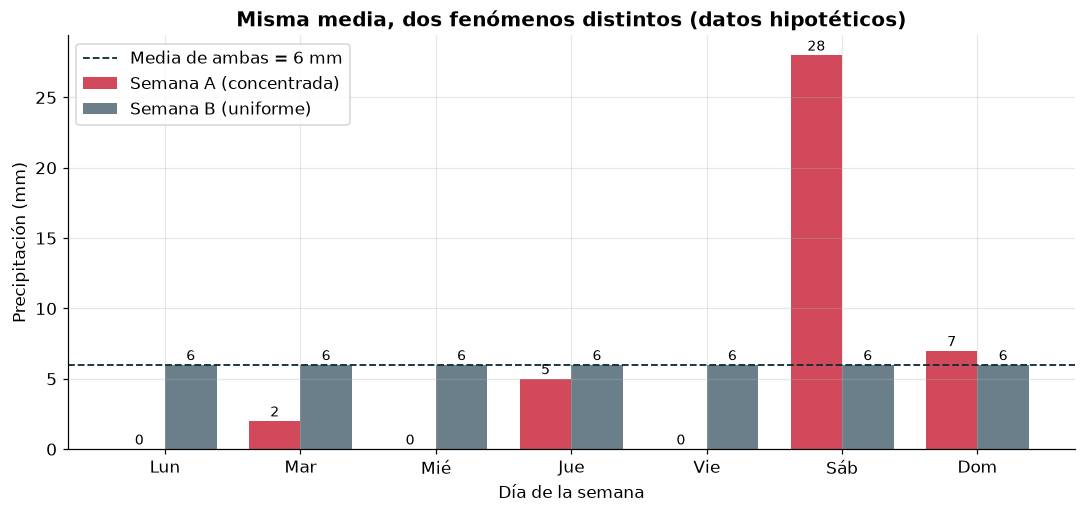

,Semana A,Semana B
Total (mm),42.00,42.00
Media (mm/día),6.00,6.00
Mediana (mm/día),2.00,6.00
Desv. estándar (mm),9.34,0.00
Máximo diario (mm),28.00,6.00
Días sin lluvia,3.00,0.00
% del total en el día más lluvioso,66.67,14.29


In [28]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x, ancho = np.arange(7), 0.38
barras_A = ax.bar(x - ancho/2, semana_A, ancho, color=CORAL, label="Semana A (concentrada)")
barras_B = ax.bar(x + ancho/2, semana_B, ancho, color=PIZARRA, label="Semana B (uniforme)")
for b in list(barras_A) + list(barras_B):
    ax.annotate(f"{b.get_height():.0f}", (b.get_x() + b.get_width()/2, b.get_height()),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.axhline(6, color=OSCURO, ls="--", lw=1.2, label="Media de ambas = 6 mm")
ax.set_xticks(x); ax.set_xticklabels(dias)
ax.set_ylabel("Precipitación (mm)"); ax.set_xlabel("Día de la semana")
ax.set_title("Misma media, dos fenómenos distintos (datos hipotéticos)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("comparacion_semanas.png", dpi=150, bbox_inches="tight")
plt.show()

tabla_AB = pd.DataFrame({"Semana A": indicadores(semana_A), "Semana B": indicadores(semana_B)})
display(tabla_AB.loc[["Total (mm)", "Media (mm/día)", "Mediana (mm/día)", "Desv. estándar (mm)",
                      "Máximo diario (mm)", "Días sin lluvia", "% del total en el día más lluvioso"]])

### Lectura estadística (lo que la media escondía)

* **Mediana:** la Semana A tiene mediana de 2 mm(la mitad de los días la precipitación fue menor o igual a 2); la media (6 mm) está *arrastrada* por un solo día extremo.
* **Dispersión:** la desviación estándar de A es ≈ 9.3 mm; la de B es 0.
* **Concentración:** el 67 % de lo que llovió en A cayó en **un solo día**.
* **Consecuencias distintas:** 28 mm en un día puede saturar un drenaje urbano o cerrar una vía rural; 6 mm diarios no.

> Con una sola medida resumen no se distinguen. **Pensar estadísticamente es preguntar qué información falta para comprender el fenómeno.**

### Del ejemplo de juguete a los datos de Caucasia
¿Pasa lo mismo con datos simulados de tres años? En vez de inventar dos semanas, **le pedimos al computador que las busque**: entre los 36 meses de la serie, ¿qué dos meses tienen casi la misma media diaria pero comportamientos más distintos?

El algoritmo encontró: 2023-10 y 2024-04


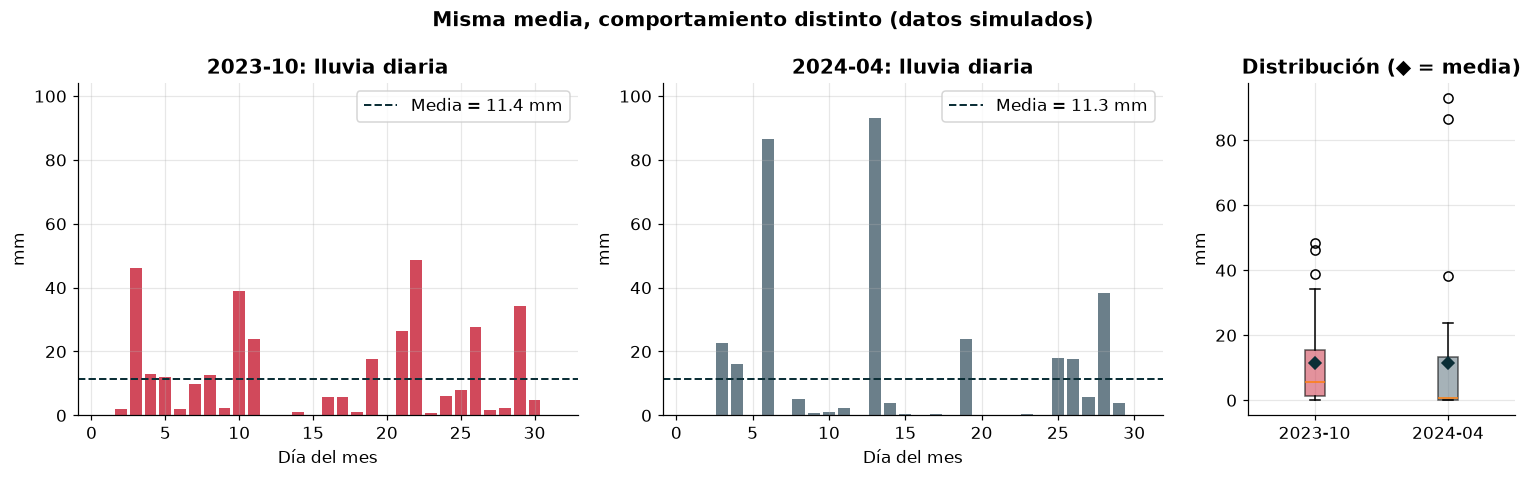

,2023-10,2024-04
Total (mm),354.40,339.70
Media (mm/día),11.43,11.32
Mediana (mm/día),5.60,0.60
Desv. estándar (mm),14.18,22.97
Máximo diario (mm),48.50,93.00
Días sin lluvia,4.00,12.00
Días con ≥ 20 mm,7.00,5.00
% del total en el día más lluvioso,13.69,27.38
Racha seca máxima (días),2.00,3.00


In [29]:
def comparar_periodos(df, periodo_a, periodo_b):
    """Compara dos meses (formato 'AAAA-MM') con gráficos e indicadores."""
    datos = {}
    for p in (periodo_a, periodo_b):
        datos[p] = df[df["fecha"].dt.to_period("M") == pd.Period(p)]["precipitacion_mm"].reset_index(drop=True)

    fig, ejes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [3, 3, 1.6]})
    tope = max(s.max() for s in datos.values()) * 1.12
    for eje, (p, s), color in zip(ejes[:2], datos.items(), (CORAL, PIZARRA)):
        eje.bar(np.arange(1, len(s) + 1), s, color=color)
        eje.axhline(s.mean(), color=OSCURO, ls="--", lw=1.3, label=f"Media = {s.mean():.1f} mm")
        eje.set_ylim(0, tope); eje.set_title(f"{p}: lluvia diaria")
        eje.set_xlabel("Día del mes"); eje.set_ylabel("mm"); eje.legend(loc="upper right")
    caja = ejes[2].boxplot(list(datos.values()), tick_labels=list(datos.keys()), patch_artist=True,
                           showmeans=True, meanprops=dict(marker="D", markerfacecolor=OSCURO, markeredgecolor=OSCURO))
    for parche, color in zip(caja["boxes"], (CORAL, PIZARRA)):
        parche.set_facecolor(color); parche.set_alpha(0.6)
    ejes[2].set_title("Distribución (◆ = media)"); ejes[2].set_ylabel("mm")
    fig.suptitle("Misma media, comportamiento distinto (datos simulados)", fontweight="bold")
    plt.tight_layout(); plt.show()

    tabla = pd.DataFrame({p: indicadores(s) for p, s in datos.items()})
    tabla.loc["Racha seca máxima (días)"] = [racha_seca_maxima(s) for s in datos.values()]
    return tabla

mes_a, mes_b = buscar_meses_parecidos(df)
print(f"El algoritmo encontró: {mes_a} y {mes_b}")
display(comparar_periodos(df, str(mes_a), str(mes_b)))

### ✋ Detente: tres preguntas, tres niveles
| Pregunta | Competencia que se evalúa |
|---|---|
| **1. Calcular.** ¿Cuál es la precipitación media diaria de cada mes? | Ejecutar procedimientos correctamente. |
| **2. Interpretar.** Si las medias son casi iguales, ¿por qué las gráficas son tan distintas? ¿Qué mes «se siente» más lluvioso y por qué? | Relacionar medidas con distribuciones y patrones. |
| **3. Investigar.** ¿Qué otros datos necesitaríamos para saber si los meses con aguaceros fuertes se asocian con inundaciones o cierres de vías en sectores de Caucasia? | Formular preguntas investigables y reconocer límites. |

**🧪 Tu turno:** cambia los periodos de la celda siguiente (formato `'AAAA-MM'`) y compara otros dos meses. ¿Cuál de las tres medidas (media, mediana, desviación) te habría permitido anticipar la diferencia?

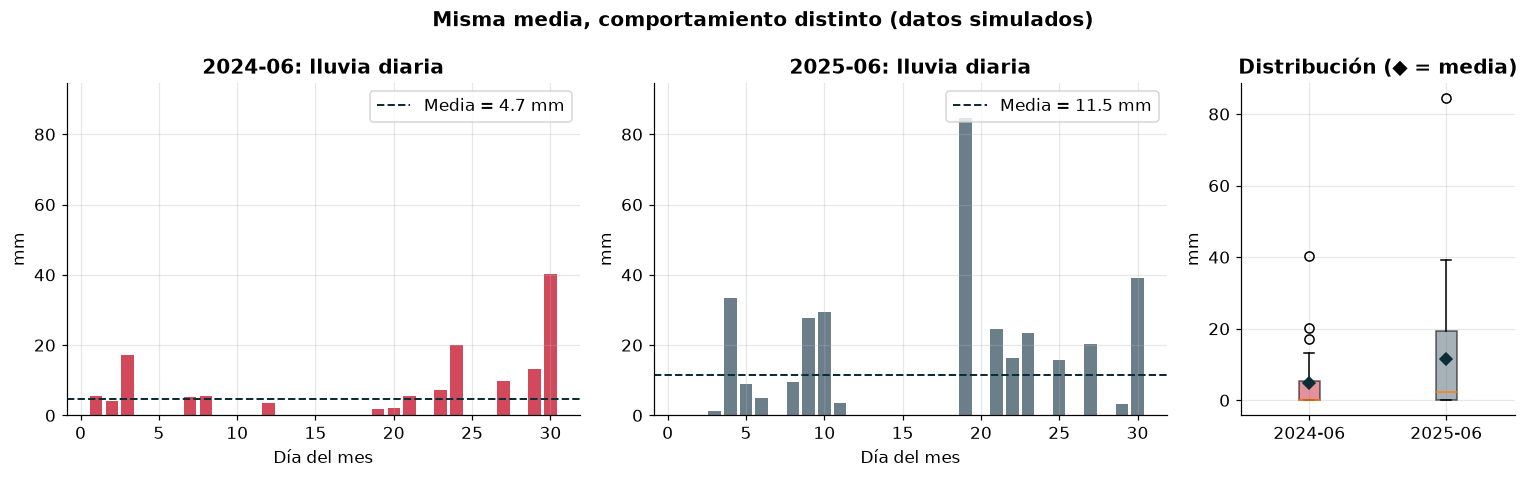

,2024-06,2025-06
Total (mm),140.90,346.30
Media (mm/día),4.70,11.54
Mediana (mm/día),0.00,2.25
Desv. estándar (mm),8.43,18.02
Máximo diario (mm),40.20,84.50
Días sin lluvia,16.00,14.00
Días con ≥ 20 mm,2.00,8.00
% del total en el día más lluvioso,28.53,24.40
Racha seca máxima (días),6.00,7.00


In [30]:
# Tu turno: otra pareja con casi la misma media (≈ 5.5 mm/día). Cambia los periodos: de '2023-01' a '2025-12'
display(comparar_periodos(df, "2024-06", "2025-06"))

---
## Nivel 3 · Enseñar a **investigar**

Ahora la pregunta no la da el profesor con la respuesta incluida; la formulan los estudiantes.

> **Pregunta de investigación:** *¿Cómo se comporta la lluvia a lo largo del año en Caucasia y qué implica para las actividades del territorio?*

Descomponemos la pregunta (pensamiento computacional) en tres sub-preguntas que podemos responder con los datos:
1. ¿Cuándo llueve más y cuánto cambia de un año a otro? *(régimen mensual y variabilidad)*
2. ¿La media representa la lluvia típica de cada mes? *(media vs. mediana)*
3. ¿Qué tan frecuentes son los aguaceros fuertes y las rachas secas? *(eventos extremos)*

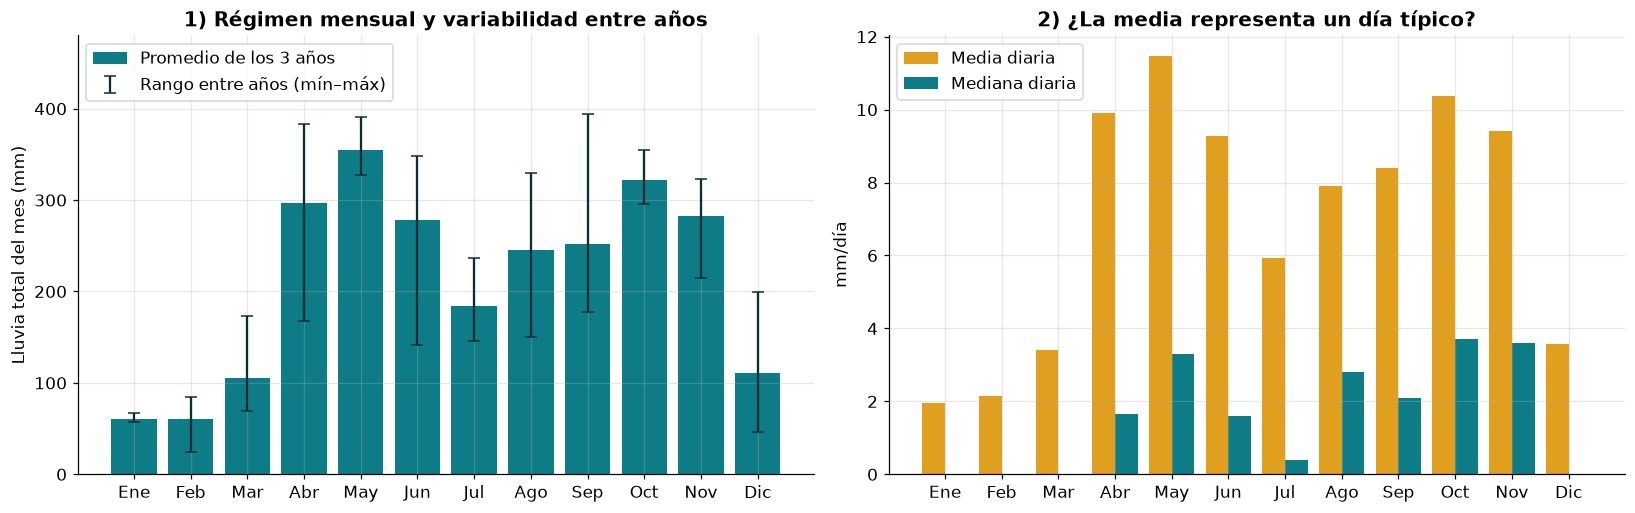

Total anual simulado: {2023: 2766.0, 2024: 2431.0, 2025: 2463.0}
Meses con mediana = 0 mm (más de la mitad de los días sin lluvia): ['Ene', 'Feb', 'Mar', 'Dic']


In [31]:
mensual = (df.groupby(["anio", "mes"])["precipitacion_mm"].sum().unstack("anio"))   # total mensual por año
promedio, minimo, maximo = mensual.mean(axis=1), mensual.min(axis=1), mensual.max(axis=1)

diaria_por_mes = df.groupby("mes")["precipitacion_mm"]
media_dia, mediana_dia = diaria_por_mes.mean(), diaria_por_mes.median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
ax1.bar(MESES, promedio, color=TEAL, label="Promedio de los 3 años")
ax1.errorbar(MESES, promedio, yerr=[promedio - minimo, maximo - promedio], fmt="none",
             ecolor=OSCURO, capsize=4, label="Rango entre años (mín–máx)")
ax1.set_title("1) Régimen mensual y variabilidad entre años")
ax1.set_ylabel("Lluvia total del mes (mm)"); ax1.set_ylim(0, 480); ax1.legend(loc="upper left")

x, ancho = np.arange(12), 0.4
ax2.bar(x - ancho/2, media_dia, ancho, color=AMBAR, label="Media diaria")
ax2.bar(x + ancho/2, mediana_dia, ancho, color=TEAL, label="Mediana diaria")
ax2.set_xticks(x); ax2.set_xticklabels(MESES)
ax2.set_title("2) ¿La media representa un día típico?"); ax2.set_ylabel("mm/día"); ax2.legend()
plt.tight_layout(); plt.show()

print(f"Total anual simulado: {df.groupby('anio')['precipitacion_mm'].sum().round(0).to_dict()}")
print(f"Meses con mediana = 0 mm (más de la mitad de los días sin lluvia): "
      f"{[MESES[m-1] for m in mediana_dia.index if mediana_dia[m] == 0]}")

**Lectura:** en casi todos los meses la **media supera a la mediana**: pocos días muy lluviosos «jalan» el promedio hacia arriba. Un estudiante que solo reporta la media diría que en abril llueve ≈ 10 mm *todos* los días; los datos dicen que la mitad de los días llueve poco o nada y unos cuantos días concentran el agua.

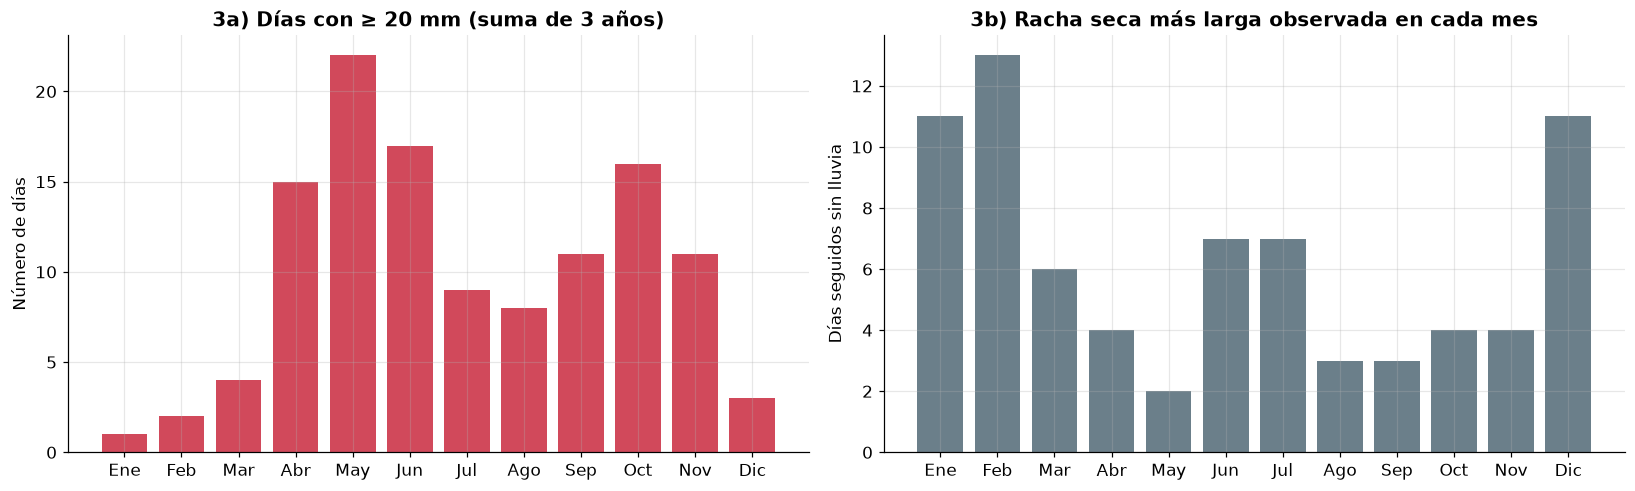

Días con ≥ 20 mm en los 3 años: 119 de 1096 (10.9 %)
Racha seca más larga de toda la serie: 13 días (mes: Feb)


In [32]:
UMBRAL = 20   # mm en un día: cámbialo y observa cómo cambia la conclusión

extremos = (df.assign(fuerte=df["precipitacion_mm"] >= UMBRAL)
              .groupby("mes")["fuerte"].sum())

rachas = (df.groupby(["anio", "mes"])["precipitacion_mm"]
            .apply(racha_seca_maxima).unstack("anio").max(axis=1))   # la peor racha seca de cada mes

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6))
ax1.bar(MESES, extremos, color=CORAL)
ax1.set_title(f"3a) Días con ≥ {UMBRAL} mm (suma de 3 años)"); ax1.set_ylabel("Número de días")
ax2.bar(MESES, rachas, color=PIZARRA)
ax2.set_title("3b) Racha seca más larga observada en cada mes"); ax2.set_ylabel("Días seguidos sin lluvia")
plt.tight_layout(); plt.show()

print(f"Días con ≥ {UMBRAL} mm en los 3 años: {int(extremos.sum())} de {len(df)} ({100*extremos.sum()/len(df):.1f} %)")
print(f"Racha seca más larga de toda la serie: {int(rachas.max())} días (mes: {MESES[int(rachas.idxmax())-1]})")

### ✋ Detente: la pregunta más importante de la sesión
> *¿Qué otros datos necesitaríamos para estudiar si las lluvias intensas están asociadas con dificultades de movilidad o inundaciones en determinados sectores de Caucasia?*

Con **solo** esta serie de lluvia **no podemos afirmar** que un aguacero cause una inundación: falta información del territorio. La tabla siguiente convierte esa reflexión en un **plan de investigación**.

In [33]:
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", None)   # no truncar texto
pd.set_option("display.width", 200)

plan = pd.DataFrame([
    ["¿Dónde se concentran los daños cuando llueve ≥ 20 mm?",
     "Reportes de emergencias por sector y fecha",
     "Gestión del riesgo municipal / registros locales",
     "Pueden estar incompletos o sub-registrar zonas rurales"],
    ["¿La lluvia de un sitio representa a todo el municipio?",
     "Lluvia en varios puntos (pluviómetros escolares)",
     "Estaciones oficiales + mediciones del colegio",
     "Una estación puede no reflejar la variación espacial"],
    ["¿Hay drenaje y obras que cambian el efecto de la lluvia?",
     "Mapas de drenaje, pendiente y uso del suelo",
     "Planeación municipal, cartografía abierta",
     "Información desactualizada o no pública"],
    ["¿El año analizado es típico?",
     "Series de 10–30 años; fenómenos El Niño / La Niña",
     "IDEAM, NASA POWER (verificar condiciones de uso)",
     "Cambios de instrumentos y vacíos en los registros"],
], columns=["Pregunta investigable", "Datos que faltan",
            "Fuente posible", "Limitación a declarar"])

display(plan)

,Pregunta investigable,Datos que faltan,Fuente posible,Limitación a declarar
0,¿Dónde se concentran los daños cuando llueve ≥ 20 mm?,Reportes de emergencias por sector y fecha,Gestión del riesgo municipal / registros locales,Pueden estar incompletos o sub-registrar zonas rurales
1,¿La lluvia de un sitio representa a todo el municipio?,Lluvia en varios puntos (pluviómetros escolares),Estaciones oficiales + mediciones del colegio,Una estación puede no reflejar la variación espacial
2,¿Hay drenaje y obras que cambian el efecto de la lluvia?,"Mapas de drenaje, pendiente y uso del suelo","Planeación municipal, cartografía abierta",Información desactualizada o no pública
3,¿El año analizado es típico?,Series de 10–30 años; fenómenos El Niño / La Niña,"IDEAM, NASA POWER (verificar condiciones de uso)",Cambios de instrumentos y vacíos en los registros


---
## Horizonte · De la estadística a la inteligencia artificial

La lluvia, la humedad y la temperatura no son independientes. 

Un modelo de *Machine Learning* sencillo (regresión lineal) **aprende** una relación a partir de datos pasados. Pero el pensamiento estadístico exige tres cuidados:

1. **Evaluar con datos que el modelo no vio:** entrenamos con 2023–2024 y probamos con 2025 (respeta el orden del tiempo).
2. **Comparar con una predicción ingenua:** «siempre el promedio». Si el modelo no la supera, no aporta.
3. **Mirar el error en las unidades del problema,** no solo un número como R², sino con MAE, RMSE.

Construiremos un modelo para ver qué variable depende de la humedad

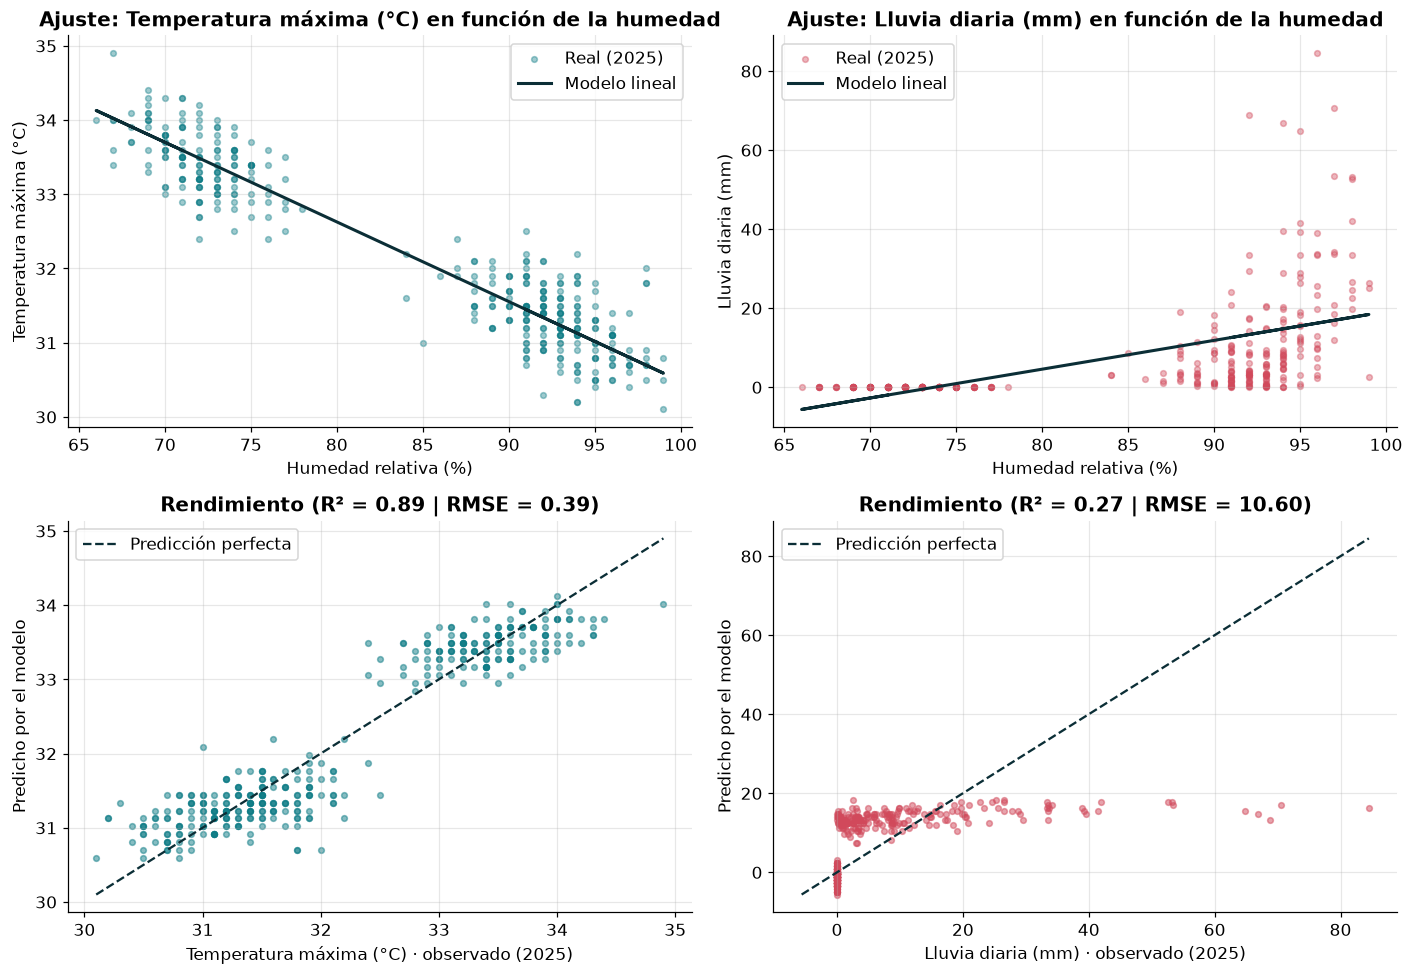

,Error del modelo (RMSE),Error de la predicción ingenua,R² (datos nuevos),Mejora frente a lo ingenuo (%)
Qué predice,,,,
Temperatura máxima (°C),0.39,1.16,0.89,66.20
Lluvia diaria (mm),10.60,12.39,0.27,14.50


In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

def evaluar_solo_humedad(df, objetivo):
    # Separar entrenamiento (2023-2024) y prueba (2025)
    train = df[df["fecha"].dt.year < 2025]
    test = df[df["fecha"].dt.year == 2025]
    
    X_train, y_train = train[["humedad_pct"]], train[objetivo]
    X_test, y_test = test[["humedad_pct"]], test[objetivo]
    
    # Entrenar modelo lineal univariado
    modelo = LinearRegression().fit(X_train, y_train)
    prediccion = modelo.predict(X_test)
    
    # Línea base ingenua (predecir siempre la media de entrenamiento)
    pred_ingenua = np.full_like(y_test, y_train.mean(), dtype=float)
    
    return {
        "prueba": test,
        "prediccion": prediccion,
        "rmse_modelo": root_mean_squared_error(y_test, prediccion),
        "rmse_ingenua": root_mean_squared_error(y_test, pred_ingenua),
        "r2_prueba": r2_score(y_test, prediccion)
    }

casos = [
    ("temp_max_C", "Temperatura máxima (°C)", TEAL),
    ("precipitacion_mm", "Lluvia diaria (mm)", CORAL)
]

resultados = []
fig, ejes = plt.subplots(2, 2, figsize=(13, 9))

for col, (objetivo, etiqueta, color) in enumerate(casos):
    r = evaluar_solo_humedad(df, objetivo)
    prueba = r["prueba"]
    real = prueba[objetivo]
    
    # Fila 0: Relación Humedad vs Variable y ajuste del modelo
    ejes[0, col].scatter(prueba["humedad_pct"], real, s=14, alpha=0.4, color=color, label="Real (2025)")
    ejes[0, col].plot(prueba["humedad_pct"], r["prediccion"], color=OSCURO, lw=2, label="Modelo lineal")
    ejes[0, col].set_xlabel("Humedad relativa (%)")
    ejes[0, col].set_ylabel(etiqueta)
    ejes[0, col].set_title(f"Ajuste: {etiqueta} en función de la humedad")
    ejes[0, col].legend()
    
    # Fila 1: Rendimiento (Observado vs Predicho)
    ejes[1, col].scatter(real, r["prediccion"], s=14, alpha=0.5, color=color)
    lim = [min(real.min(), r["prediccion"].min()), max(real.max(), r["prediccion"].max())]
    ejes[1, col].plot(lim, lim, color=OSCURO, ls="--", label="Predicción perfecta")
    ejes[1, col].set_xlabel(f"{etiqueta} · observado (2025)")
    ejes[1, col].set_ylabel("Predicho por el modelo")
    ejes[1, col].set_title(f"Rendimiento (R² = {r['r2_prueba']:.2f} | RMSE = {r['rmse_modelo']:.2f})")
    ejes[1, col].legend()
    
    resultados.append({
        "Qué predice": etiqueta,
        "Error del modelo (RMSE)": round(r["rmse_modelo"], 2),
        "Error de la predicción ingenua": round(r["rmse_ingenua"], 2),
        "R² (datos nuevos)": round(r["r2_prueba"], 2),
        "Mejora frente a lo ingenuo (%)": round(100 * (1 - r["rmse_modelo"] / r["rmse_ingenua"]), 1)
    })

plt.tight_layout()
plt.savefig("predicciones_rendimiento.png", dpi=150)
plt.show()

display(pd.DataFrame(resultados).set_index("Qué predice"))

**Lectura crítica**
* La humedad predice bien la **temperatura máxima** (el error se reduce ≈ 43 % frente a la predicción ingenua).
* Para la **lluvia diaria** el modelo mejora poco y su error sigue siendo grande: la lluvia es muy asimétrica, con muchos ceros y pocos días extremos, y una recta no captura eso (¡incluso predice «lluvias negativas» en algunos días!). *Un modelo puede ejecutarse sin errores y aun así ser poco útil.*
* Recuerda: estos datos son simulados y la relación entre variables **se programó** en la simulación; con datos reales habría que verificarlo.

> Esta es la conexión con la IA: **variables, distribuciones, error, muestreo (entrenamiento/prueba) e incertidumbre** son ideas estadísticas que los estudiantes necesitan para cuestionar a los algoritmos.

---
## Cierre: lo que cambió entre calcular y pensar

| Mismo dato: la media de 6–11 mm | **Calcular** | **Pensar estadísticamente** |
|---|---|---|
| Pregunta | ¿Cuánto da la media? | ¿Qué significa, qué oculta y qué más necesito saber? |
| Evidencia | Un número | Número + gráfico + mediana + dispersión + contexto |
| Python sirve para… | Ahorrar tiempo | Experimentar, buscar patrones y verificar |
| Resultado | Respuesta correcta | Explicación argumentada con límites declarados |

### Una progresión para el aula
* **Primaria:** registrar lluvia con un pluviómetro casero, tablas de frecuencia y pictogramas («días con lluvia / sin lluvia»); preguntar *¿cuál semana fue más lluviosa y por qué?*
* **Secundaria básica:** media, mediana, rango y desviación; construir gráficos; comparar dos semanas o meses con la misma media.
* **Educación media:** series de tiempo, correlación y regresión; entrenar/evaluar un modelo; discutir sesgos y límites de las predicciones.

### Tres afirmaciones para llevar
1. **Enseñar estadística es enseñar a pensar:** no basta calcular, hay que interpretar.
2. **Enseñar estadística es enseñar a investigar:** preguntas → datos → patrones → explicaciones → límites.
3. **Enseñar estadística es preparar para comprender la IA:** datos, incertidumbre, error y sesgo.

---
### ❓ ¿Estamos enseñando a nuestros estudiantes a **calcular con datos** o a **pensar con datos**?

# Sobre los referentes o sustentos teóricos 

### 1. Chris Wild y Maxine Pfannkuch (Didáctica y Epistemología del Pensamiento Estadístico)

* **Aporte teórico:** Su marco del **Ciclo Investigativo PPDAC** (*Problem, Plan, Data, Analysis, Conclusion*) y las dimensiones del pensamiento estadístico (transnumeración, consideración de la variación, razonamiento con modelos estadísticos e integración del contexto).
* **Conexión con tu material:** En la **diapositiva 8** (*Nivel 3 · Investigar*), presentas explícitamente el ciclo de 7 pasos (*Preguntar, Recolectar, Organizar, Explorar, Representar, Interpretar, Comunicar*) que adapta el modelo PPDAC al aula de primaria y bachillerato. Asimismo, la comparación entre la **Semana A y la Semana B** (diapositivas 5-6 y celdas del Nivel 2) materializa el concepto de *transnumeración* y la necesidad de comprender la variación más allá de un resumen numérico aislado como la media.

### 2. Jeannette Wing y Karen Brennan / Mitchel Resnick (Tecnología y Pensamiento Computacional)

* **Aporte teórico:** Jeannette Wing (2006) define el **pensamiento computacional** mediante pilares como la abstracción, la descomposición y el diseño de algoritmos; Brennan y Resnick (2012) amplían este marco hacia las prácticas computacionales de iteración, depuración y reutilización en entornos educativos.
* **Conexión con tu material:** En el cuaderno de Jupyter, bajo la sección *«Caja de herramientas: tres funciones (pensamiento computacional en acción)»*, vinculas explícitamente el código en Python con estas categorías: la función `indicadores(serie)` ejemplifica la **abstracción** (decidir qué medidas describen el fenómeno climático), mientras que `buscar_meses_parecidos(df)` y `racha_seca_maxima(serie)` aplican el **diseño algorítmico y la automatización** para descubrir patrones ocultos en los 1096 días de datos.



### 3. Seymour Papert y Uri Wilensky (Epistemología Construccionista y Modelado Computacional)

* **Aporte teórico:** El **Construccionismo** de Papert sostiene que el aprendizaje ocurre de manera más profunda cuando el estudiante construye artefactos públicos y manipulables mediante la programación. Uri Wilensky extiende esto hacia el modelado basado en agentes y la simulación de fenómenos complejos para comprender sistemas probabilísticos.
* **Conexión con tu material:** El cuaderno de Jupyter funciona como un laboratorio construccionista interactivo donde los estudiantes no solo consumen datos, sino que inspeccionan el **generador estocástico** (`simular_caucasia()`), cuestionan sus supuestos (diapositiva 3 y sección 0 del cuaderno) y modifican parámetros para experimentar qué ocurre cuando la distribución cambia, cumpliendo la premisa de que *Python sirve para explorar, contrastar y verificar*.



### 4. Carmen Batanero y Joan Garfield (Didáctica de la Estadística y Alfabetización Estadística)

* **Aporte teórico:** Sus investigaciones en educación estadística distinguen entre el dominio procedimental/algorítmico (calcular fórmulas) y la **alfabetización y el razonamiento estadístico** (*Statistical Literacy and Reasoning*), señalando los sesgos cognitivos habituales al interpretar medidas de tendencia central sin considerar la asimetría o la dispersión.
* **Conexión con tu material:** Es el eje central de toda tu ponencia (*«¿Calcular o pensar con datos?»*, diapositiva 1). La progresión estructurada en tres niveles (**Nivel 1: Calcular $\rightarrow$ Nivel 2: Interpretar $\rightarrow$ Nivel 3: Investigar**, diapositiva 2 y 13) y la demostración de cómo la media diaria (6.0 mm/día en las semanas o 9.89 vs. 1.65 en abril) oculta los aguaceros extremos, atacan directamente el obstáculo epistemológico identificado por Batanero y Garfield sobre la comprensión superficial de los promedios.

### 5. David Touretzky, Christina Gardner-McCune y el marco AI4K12 (Educación para la Inteligencia Artificial, ML y DL)

* **Aporte teórico:** La iniciativa **AI4K12** (*Five Big Ideas in AI*) establece los estándares curriculares para enseñar Inteligencia Artificial en primaria y secundaria, destacando que los estudiantes deben comprender cómo las máquinas **aprenden de los datos** (Machine Learning / Deep Learning), cómo se representan los modelos y cuáles son sus límites, sesgos y márgenes de error.
* **Conexión con tu material:** La **diapositiva 12** (*Horizonte · IA: evaluar, no solo predecir*) y el bloque final del cuaderno aterrizan directamente estas ideas. Al entrenar un modelo con datos de 2023–2024 y evaluarlo con datos no vistos de 2025 ($R^2 = 0.67$ para temperatura frente a $R^2 = 0.24$ y predicciones físicamente imposibles de lluvia negativa), ilustras el fundamento epistemológico del aprendizaje automático y profundo: un algoritmo de ML/DL no "entiende" el territorio de Caucasia, sino que optimiza patrones estadísticos cuya validez depende de la calidad de los datos y de la evaluación crítica del error.

# Bibliografía en normas APA
### 1. Pensamiento Estadístico y Ciclo Investigativo (PPDAC)

* **Wild, C. J., & Pfannkuch, M. (1999).** Statistical thinking in empirical enquiry. *International Statistical Review*, 67(3), 223–248. [https://doi.org/10.1111/j.1751-5823.1999.tb00442.x](https://www.google.com/search?q=https://doi.org/10.1111/j.1751-5823.1999.tb00442.x)
> *Nota de vínculo:* En este artículo seminal definen las cuatro dimensiones del pensamiento estadístico, el concepto de *transnumeración* y el ciclo investigativo PPDAC (*Problem, Plan, Data, Analysis, Conclusion*).



### 2. Pensamiento Computacional

* **Wing, J. M. (2006).** Computational thinking. *Communications of the ACM*, 49(3), 33–35. [https://doi.org/10.1145/1118178.1118215](https://doi.org/10.1145/1118178.1118215)
> *Nota de vínculo:* Publicación fundacional donde establece la abstracción, la descomposición y el diseño algorítmico como competencias transversales para todas las disciplinas, más allá de las ciencias de la computación.


* **Brennan, K., & Resnick, M. (2012).** *New frameworks for studying and assessing the development of computational thinking*. Proceedings of the 2012 Annual Meeting of the American Educational Research Association (AERA), Vancouver, Canada.
> *Nota de vínculo:* Complementa a Wing al desglosar el pensamiento computacional en conceptos, prácticas (iterar, depurar, abstraer y modularizar) y perspectivas aplicables en el aula.



### 3. Epistemología Construccionista y Simulación Computacional

* **Papert, S. (1980).** *Mindstorms: Children, computers, and powerful ideas*. Basic Books.
> *Nota de vínculo:* Obra clásica donde formula el construccionismo y demuestra cómo programar y manipular modelos computacionales permite a los estudiantes construir comprensión matemática y probabilística profunda.


* **Wilensky, U., & Rand, W. (2015).** *An introduction to agent-based modeling: Modeling natural, social, and engineered complex systems with NetLogo*. MIT Press.
> *Nota de vínculo:* Desarrolla el uso de simulaciones computacionales y generadores estocásticos en educación para explorar sistemas complejos, variabilidad y fenómenos emergentes mediante la experimentación con código.

### 4. Didáctica de la Estadística y Alfabetización Estadística

* **Batanero, C. (2001).** *Didáctica de la estadística*. Grupo de Educación Estadística, Universidad de Granada.
> *Nota de vínculo:* Texto de referencia en español donde analiza la diferencia entre el cálculo algorítmico y la comprensión conceptual, abordando los errores frecuentes en la interpretación de medidas de tendencia central y dispersión.


* **Garfield, J., & Ben-Zvi, D. (2008).** *Developing students' statistical reasoning: Connecting research and teaching practice*. Springer. [https://doi.org/10.1007/978-1-4020-8383-9](https://doi.org/10.1007/978-1-4020-8383-9)
> *Nota de vínculo:* Profundiza en la distinción entre alfabetización (*literacy*), razonamiento (*reasoning*) y pensamiento (*thinking*) estadístico, fundamentando por qué las tareas deben ir más allá de la aplicación mecánica de fórmulas.



### 5. Educación en Inteligencia Artificial, Machine Learning y Deep Learning

* **Touretzky, D., Gardner-McCune, C., Martin, F., & Seehorn, D. (2019).** Envisioning AI for K-12: What should every child know about AI? *Proceedings of the AAAI Conference on Artificial Intelligence*, 33(01), 9795–9799. [https://doi.org/10.1609/aaai.v33i01.33019795](https://www.google.com/search?q=https://doi.org/10.1609/aaai.v33i01.33019795)
> *Nota de vínculo:* Presenta las «Cinco Grandes Ideas de la IA» (iniciativa AI4K12), estableciendo cómo enseñar en educación básica y media que las máquinas aprenden de los datos, construyen modelos estadísticos y tienen limitaciones, sesgos y errores de generalización.